# MLflow Tutorial

This notebook walks through the core MLflow capabilities using a local tracking server.

**Prerequisites:** start the tracking server with `docker compose up -d` from this directory.

---

## Contents
1. [Connect to the tracking server](#1-connect)
2. [Experiments](#2-experiments)
3. [Manual logging — params, metrics, tags](#3-manual-logging)
4. [Autolog with scikit-learn](#4-autolog)
5. [Logging metrics per step (training curves)](#5-step-logging)
6. [Logging artifacts (plots, files)](#6-artifacts)
7. [Logging a model and loading it back](#7-model)
8. [Model Registry — register, stage, promote](#8-registry)
9. [Searching and comparing runs programmatically](#9-search)

## 0 — Imports

In [1]:
import os
import mlflow
import mlflow.sklearn
from mlflow import MlflowClient

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

print(f"MLflow version: {mlflow.__version__}")

MLflow version: 2.14.1


## 1 — Connect to the tracking server <a id='1-connect'></a>

By default MLflow logs locally to `./mlruns`. Setting a tracking URI points it at a real server.
Open http://localhost:5000 in your browser to see the UI.

In Docker, `MLFLOW_TRACKING_URI` is injected by docker-compose so the notebook talks to the `mlflow` service over the compose network.

In [2]:
# In Docker: MLFLOW_TRACKING_URI=http://mlflow:5000 (set by docker-compose)
# Locally: falls back to localhost
TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI", "http://localhost:5000")
mlflow.set_tracking_uri(TRACKING_URI)
print(f"Tracking URI: {TRACKING_URI}")

# Smoke-test: list experiments — raises if the server is unreachable
client = MlflowClient()
experiments = client.search_experiments()
print(f"Connected. Existing experiments: {[e.name for e in experiments]}")

Tracking URI: http://mlflow:5001
Connected. Existing experiments: ['Default']


## 2 — Experiments <a id='2-experiments'></a>

An **experiment** is a named container for runs — think of it as a project or a model family.
Runs that share a purpose should live in the same experiment so you can compare them side-by-side.

In [4]:
EXPERIMENT_NAME = "wine-classification-2"

# set_experiment creates it if it doesn't exist, or reuses it if it does
mlflow.set_experiment(EXPERIMENT_NAME)

experiment = client.get_experiment_by_name(EXPERIMENT_NAME)
print(f"Experiment ID : {experiment.experiment_id}")
print(f"Artifact root : {experiment.artifact_location}")

2026/08/26 15:23:37 INFO mlflow.tracking.fluent: Experiment with name 'wine-classification-2' does not exist. Creating a new experiment.


Experiment ID : 2
Artifact root : /mlflow/artifacts/2


## 3 — Manual logging — params, metrics, tags <a id='3-manual-logging'></a>

The most explicit way to use MLflow. You control exactly what gets recorded.

- **Params** — fixed before the run (hyperparameters, dataset versions). Logged once.
- **Metrics** — scalar numbers that result from training (accuracy, loss). Can be logged at multiple steps.
- **Tags** — free-form key/value metadata (author, git SHA, notes).

In [5]:
# --- Data ---
wine = load_wine()
X, y = wine.data, wine.target
feature_names = wine.feature_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Classes: {wine.target_names}")

Train: (142, 13), Test: (36, 13)
Classes: ['class_0' 'class_1' 'class_2']


In [6]:
params = {
    "n_estimators": 50,
    "max_depth": 4,
    "random_state": 42,
}

with mlflow.start_run(run_name="manual-rf-baseline") as run:
    # --- Log params (once, before/after training) ---
    mlflow.log_params(params)

    # --- Train ---
    model = RandomForestClassifier(**params)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    # --- Log metrics ---
    mlflow.log_metrics({
        "accuracy": accuracy_score(y_test, preds),
        "f1_macro": f1_score(y_test, preds, average="macro"),
    })

    # --- Tags: free-form metadata ---
    mlflow.set_tags({
        "dataset": "sklearn-wine",
        "model_type": "RandomForest",
        "note": "manual baseline",
    })

    print(f"Run ID  : {run.info.run_id}")
    print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
    print(f"F1 macro: {f1_score(y_test, preds, average='macro'):.4f}")

2026/08/26 15:24:14 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



Run ID  : 92b3f2e51a274b348f7a59880831938e
Accuracy: 1.0000
F1 macro: 1.0000


## 4 — Autolog with scikit-learn <a id='4-autolog'></a>

`mlflow.sklearn.autolog()` automatically captures:
- All estimator hyperparameters as params
- Training metrics
- The fitted model as an artifact
- A feature importance plot (for tree models)

One line replaces dozens of `log_*` calls. You can still add manual calls on top.

In [7]:
mlflow.sklearn.autolog(
    log_input_examples=True,    # saves a sample of training data as artifact
    log_model_signatures=True,  # infers input/output schema from the data
    log_models=True,
    silent=True,
)

with mlflow.start_run(run_name="autolog-rf") as run:
    model_auto = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
    model_auto.fit(X_train, y_train)

    # You can still add manual tags on top of autolog
    mlflow.set_tag("dataset", "sklearn-wine")

    preds_auto = model_auto.predict(X_test)
    print(f"Run ID  : {run.info.run_id}")
    print(f"Accuracy: {accuracy_score(y_test, preds_auto):.4f}")

# Turn autolog off so the rest of the notebook stays explicit
mlflow.sklearn.autolog(disable=True)

/usr/local/lib/python3.11/site-packages/sklearn/metrics/_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(


Run ID  : 9cb826e335344eee83cbda6b72ab3adf
Accuracy: 1.0000


## 5 — Logging metrics per step (training curves) <a id='5-step-logging'></a>

Pass `step=` to `log_metric` to record a metric at multiple points in time.
MLflow plots it as a curve in the UI — useful for loss curves, learning curves, etc.

Here we simulate a learning curve by training on increasing subsets of the data.

In [8]:
train_sizes = [0.2, 0.4, 0.6, 0.8, 1.0]

with mlflow.start_run(run_name="learning-curve") as run:
    mlflow.log_params({"n_estimators": 100, "max_depth": 6, "random_state": 42})
    mlflow.set_tag("dataset", "sklearn-wine")

    for step, frac in enumerate(train_sizes):
        n = max(1, int(len(X_train) * frac))
        X_sub, y_sub = X_train[:n], y_train[:n]

        clf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
        clf.fit(X_sub, y_sub)

        train_acc = accuracy_score(y_sub, clf.predict(X_sub))
        val_acc   = accuracy_score(y_test, clf.predict(X_test))

        # step= makes these time-series in the MLflow UI
        mlflow.log_metric("train_accuracy", train_acc, step=step)
        mlflow.log_metric("val_accuracy",   val_acc,   step=step)
        mlflow.log_metric("train_size",     n,         step=step)

        print(f"  step {step} | n={n:3d} | train={train_acc:.3f} | val={val_acc:.3f}")

    print(f"\nRun ID: {run.info.run_id}")

  step 0 | n= 28 | train=1.000 | val=0.944
  step 1 | n= 56 | train=1.000 | val=1.000
  step 2 | n= 85 | train=1.000 | val=0.972
  step 3 | n=113 | train=1.000 | val=1.000
  step 4 | n=142 | train=1.000 | val=1.000

Run ID: ef4b4005ea18410a8b6b05c66fc8e39e


## 6 — Logging artifacts (plots, files) <a id='6-artifacts'></a>

An **artifact** is any file you want to attach to a run: plots, serialized objects, data samples, reports.
They are stored in the artifact store (local filesystem here, GCS in production).

In [9]:
import tempfile

def make_confusion_matrix_fig(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, colorbar=False)
    ax.set_title("Confusion matrix")
    plt.tight_layout()
    return fig

def make_feature_importance_fig(model, feature_names):
    importances = pd.Series(model.feature_importances_, index=feature_names).sort_values()
    fig, ax = plt.subplots(figsize=(7, 5))
    importances.plot(kind="barh", ax=ax)
    ax.set_title("Feature importances")
    ax.set_xlabel("Mean decrease in impurity")
    plt.tight_layout()
    return fig


with mlflow.start_run(run_name="artifacts-demo") as run:
    params = {"n_estimators": 150, "max_depth": 5, "random_state": 42}
    mlflow.log_params(params)

    clf = RandomForestClassifier(**params)
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)

    acc = accuracy_score(y_test, preds)
    f1  = f1_score(y_test, preds, average="macro")
    mlflow.log_metrics({"accuracy": acc, "f1_macro": f1})

    with tempfile.TemporaryDirectory() as tmp:
        # Confusion matrix plot
        fig = make_confusion_matrix_fig(y_test, preds, wine.target_names)
        path = os.path.join(tmp, "confusion_matrix.png")
        fig.savefig(path); plt.close(fig)
        mlflow.log_artifact(path, artifact_path="plots")

        # Feature importance plot
        fig = make_feature_importance_fig(clf, feature_names)
        path = os.path.join(tmp, "feature_importances.png")
        fig.savefig(path); plt.close(fig)
        mlflow.log_artifact(path, artifact_path="plots")

        # Plain text report
        path = os.path.join(tmp, "summary.txt")
        with open(path, "w") as f:
            f.write(f"Model   : RandomForest\n")
            f.write(f"Params  : {params}\n")
            f.write(f"Accuracy: {acc:.4f}\n")
            f.write(f"F1 macro: {f1:.4f}\n")
        mlflow.log_artifact(path)

    print(f"Run ID: {run.info.run_id}")
    print("Artifacts: plots/confusion_matrix.png, plots/feature_importances.png, summary.txt")

Run ID: de8431d689074153b6fd49605abaeea7
Artifacts: plots/confusion_matrix.png, plots/feature_importances.png, summary.txt


## 7 — Logging a model and loading it back <a id='7-model'></a>

MLflow stores your model with a standardised format (`MLmodel`).
This lets you load it back without knowing which library trained it.

`infer_signature` captures the expected input/output schema from real data,
which MLflow uses to validate inputs at serve time.

In [10]:
from mlflow.models.signature import infer_signature

with mlflow.start_run(run_name="model-logging-demo") as run:
    params = {"n_estimators": 200, "max_depth": 6, "random_state": 42}
    mlflow.log_params(params)

    clf = RandomForestClassifier(**params)
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)

    mlflow.log_metrics({
        "accuracy": accuracy_score(y_test, preds),
        "f1_macro": f1_score(y_test, preds, average="macro"),
    })

    signature = infer_signature(X_train, clf.predict(X_train))

    model_info = mlflow.sklearn.log_model(
        sk_model=clf,
        artifact_path="model",
        signature=signature,
        input_example=X_train[:3],
    )

    logged_model_uri = model_info.model_uri
    print(f"Run ID   : {run.info.run_id}")
    print(f"Model URI: {logged_model_uri}")

Run ID   : 3d0764af451344e08c8c64b677ef73e9
Model URI: runs:/3d0764af451344e08c8c64b677ef73e9/model


/usr/local/lib/python3.11/site-packages/_distutils_hack/__init__.py:15: UserWarning: Distutils was imported before Setuptools, but importing Setuptools also replaces the `distutils` module in `sys.modules`. This may lead to undesirable behaviors or errors. To avoid these issues, avoid using distutils directly, ensure that setuptools is installed in the traditional way (e.g. not an editable install), and/or make sure that setuptools is always imported before distutils.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/_distutils_hack/__init__.py:30: UserWarning: Setuptools is replacing distutils. Support for replacing an already imported distutils is deprecated. In the future, this condition will fail. Register concerns at https://github.com/pypa/setuptools/issues/new?template=distutils-deprecation.yml
  warnings.warn(


In [11]:
# Load the model back and run inference.
# mlflow.pyfunc.load_model returns a generic wrapper — same call
# regardless of the underlying library (sklearn, XGBoost, PyTorch, etc.)

loaded_model = mlflow.pyfunc.load_model(logged_model_uri)

sample = X_test[:5]
print(f"Predicted : {loaded_model.predict(sample)}")
print(f"True labels: {y_test[:5]}")

Predicted : [0 2 0 1 1]
True labels: [0 2 0 1 1]


## 8 — Model Registry — register, stage, promote <a id='8-registry'></a>

The **Model Registry** adds lifecycle management on top of run artifacts:
- A **registered model** has a name and can have multiple **versions**.
- Each version can have **aliases** (e.g. `champion`, `challenger`) that your serving code references.
- No more hardcoded run IDs — just ask for `models:/wine-classifier@champion`.

> MLflow 2.9+ replaced the old `Staging/Production` stages with free-form aliases.

In [17]:
MODEL_NAME = "wine-classifier-2"

# Register the model logged in section 7
registered = mlflow.register_model(
    model_uri=logged_model_uri,
    name=MODEL_NAME,
)

print(f"Registered model: {registered.name}")
print(f"Version         : {registered.version}")
print(f"Status          : {registered.status}")

Successfully registered model 'wine-classifier-2'.
2026/08/26 15:28:14 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: wine-classifier-2, version 1


Registered model: wine-classifier-2
Version         : 1
Status          : READY


Created version '1' of model 'wine-classifier-2'.


In [18]:
# Assign a "champion" alias — this is what production serving code will reference
client.set_registered_model_alias(MODEL_NAME, "champion", registered.version)

client.update_model_version(
    name=MODEL_NAME,
    version=registered.version,
    description="RandomForest n=200 depth=6 — tutorial baseline.",
)

print(f"Alias champion -> version {registered.version}")

Alias champion -> version 1


In [19]:
# Train a challenger and register it as a new version
with mlflow.start_run(run_name="challenger-gbt") as run:
    params_gbt = {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05, "random_state": 42}
    mlflow.log_params(params_gbt)

    gbt = GradientBoostingClassifier(**params_gbt)
    gbt.fit(X_train, y_train)
    preds_gbt = gbt.predict(X_test)
    acc_gbt = accuracy_score(y_test, preds_gbt)

    mlflow.log_metrics({
        "accuracy": acc_gbt,
        "f1_macro": f1_score(y_test, preds_gbt, average="macro"),
    })

    sig = infer_signature(X_train, gbt.predict(X_train))
    gbt_info = mlflow.sklearn.log_model(gbt, artifact_path="model", signature=sig)
    print(f"GBT accuracy: {acc_gbt:.4f}")

challenger = mlflow.register_model(gbt_info.model_uri, MODEL_NAME)
client.set_registered_model_alias(MODEL_NAME, "challenger", challenger.version)
print(f"Alias challenger -> version {challenger.version}")

/usr/local/lib/python3.11/site-packages/_distutils_hack/__init__.py:15: UserWarning: Distutils was imported before Setuptools, but importing Setuptools also replaces the `distutils` module in `sys.modules`. This may lead to undesirable behaviors or errors. To avoid these issues, avoid using distutils directly, ensure that setuptools is installed in the traditional way (e.g. not an editable install), and/or make sure that setuptools is always imported before distutils.
  warnings.warn(
/usr/local/lib/python3.11/site-packages/_distutils_hack/__init__.py:30: UserWarning: Setuptools is replacing distutils. Support for replacing an already imported distutils is deprecated. In the future, this condition will fail. Register concerns at https://github.com/pypa/setuptools/issues/new?template=distutils-deprecation.yml
  warnings.warn(
Registered model 'wine-classifier-2' already exists. Creating a new version of this model...
2026/08/26 15:28:21 INFO mlflow.store.model_registry.abstract_store: W

GBT accuracy: 0.8889
Alias challenger -> version 2


In [20]:
# Load by alias — this is what your serving code should do
champion_model    = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}@champion")
challenger_model  = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}@challenger")

sample = pd.DataFrame(X_test[:5], columns=feature_names)
print("champion   predictions:", champion_model.predict(sample))
print("challenger predictions:", challenger_model.predict(sample))
print("true labels           :", y_test[:5])

champion   predictions: [0 2 0 1 1]
challenger predictions: [0 1 0 0 1]
true labels           : [0 2 0 1 1]


In [21]:
# Automated promotion: if challenger beats champion, move the alias
acc_champion   = accuracy_score(y_test, champion_model.predict(X_test))
acc_challenger = accuracy_score(y_test, challenger_model.predict(X_test))

print(f"Champion   accuracy: {acc_champion:.4f}")
print(f"Challenger accuracy: {acc_challenger:.4f}")

if acc_challenger > acc_champion:
    client.set_registered_model_alias(MODEL_NAME, "champion", challenger.version)
    print(f"Promoted challenger (v{challenger.version}) to champion")
else:
    print("Champion remains unchanged")

Champion   accuracy: 1.0000
Challenger accuracy: 0.8889
Champion remains unchanged


## 9 — Searching and comparing runs programmatically <a id='9-search'></a>

The MLflow UI is great for visual comparison, but sometimes you need runs in code —
for automated promotion logic, reporting, or dashboards.

In [22]:
# search_runs returns a pandas DataFrame
# Filter syntax is SQL-like
runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT_NAME],
    filter_string="metrics.accuracy > 0.9",
    order_by=["metrics.accuracy DESC"],
)

cols = ["tags.mlflow.runName", "metrics.accuracy", "metrics.f1_macro",
        "params.n_estimators", "params.max_depth"]
available = [c for c in cols if c in runs.columns]
print(runs[available].to_string(index=False))

tags.mlflow.runName  metrics.accuracy  metrics.f1_macro params.n_estimators params.max_depth
 model-logging-demo               1.0               1.0                 200                6
     artifacts-demo               1.0               1.0                 150                5
 manual-rf-baseline               1.0               1.0                  50                4


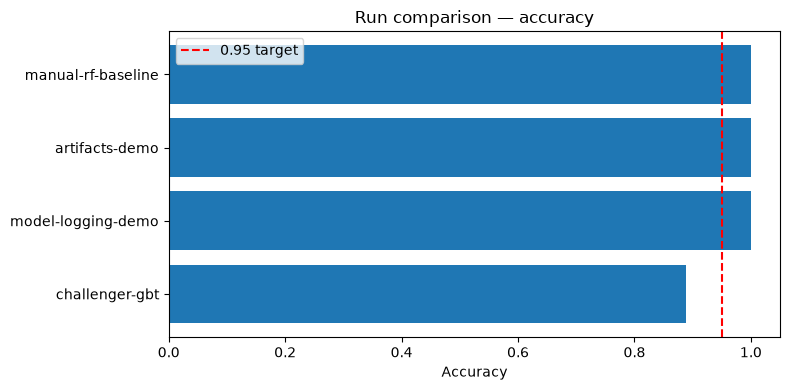

In [23]:
# Visual comparison across all runs
all_runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME])
acc_col  = "metrics.accuracy"
name_col = "tags.mlflow.runName"

if acc_col in all_runs.columns:
    valid = all_runs.dropna(subset=[acc_col]).copy()
    labels = valid[name_col] if name_col in valid.columns else valid["run_id"].str[:8]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(labels, valid[acc_col])
    ax.set_xlabel("Accuracy")
    ax.set_title("Run comparison — accuracy")
    ax.axvline(0.95, color="red", linestyle="--", label="0.95 target")
    ax.legend()
    plt.tight_layout()
    plt.show()

In [24]:
# List all registered versions
for v in client.search_model_versions(f"name='{MODEL_NAME}'"):
    print(f"  v{v.version} | run={v.run_id[:8]} | aliases={v.aliases} | {v.description[:50]}")

  v2 | run=13b30588 | aliases=[] | 
  v1 | run=3d0764af | aliases=[] | RandomForest n=200 depth=6 — tutorial baseline.


---

## Summary

| Concept | API | Use when |
|---|---|---|
| **Experiment** | `mlflow.set_experiment()` | Group related runs |
| **Run** | `mlflow.start_run()` | One training trial |
| **Params** | `mlflow.log_params()` | Hyperparameters (logged once) |
| **Metrics** | `mlflow.log_metric(step=)` | Training/eval scores, loss curves |
| **Tags** | `mlflow.set_tags()` | Free-form metadata |
| **Artifacts** | `mlflow.log_artifact()` | Plots, files, data samples |
| **Model** | `mlflow.sklearn.log_model()` | Versioned, loadable model |
| **Registry** | `mlflow.register_model()` | Lifecycle management |
| **Alias** | `client.set_registered_model_alias()` | Pointer your serving code uses |
| **Search** | `mlflow.search_runs()` | Programmatic comparison / promotion |

In [ ]:
v1.1.2